<a href="https://colab.research.google.com/github/clin0603/csci3052u-group-project/blob/main/Milestone_5_Final_Experiments_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 5: Final Experiments and Analysis
**Team Remedial Finance**

Train: 2007. Validation: 2008. Final test: 2009. The primary data are the randomized CSVs already used in the team repository.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 1. Data Source

We use historical Nevada HMDA mortgage application data, randomly sampled at 40,000 records per year before filtering for approval and denial outcomes.

In [15]:
# Create folder in Colab
!mkdir -p Random_Mortgage_Data
# Download randomized datasets into the folder
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data07.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data07.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data08.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data08.csv
!wget -q -O Random_Mortgage_Data/Random_Mortgage_Data09.csv https://raw.githubusercontent.com/clin0603/csci3052u-group-project/main/Random_Mortgage_Data/Random_Mortgage_Data09.csv

## 2. Working pipeline and baselines
Actions 1 and 2 map to approved (1); action 3 maps to denied (0); other outcomes are excluded. Only loan amount, income, loan type and loan purpose enter the model. Numeric medians, missing indicators, scaling and one-hot encoding are fitted on 2007 only.

Majority classifier: always predicts the 2007 majority class.

We compare **kNN** and **L2-regularized logistic regression** against the majority baseline. We test `k` values of 5, 15, 31, 61, and 101 and `C` values of 0.01, 0.1, 1, 10, and 100. We train on 2007, select both settings using 2008 validation ROC-AUC, and evaluate on 2009 without refitting.

In [16]:
def run():
    folder = Path("Random_Mortgage_Data")
    results_dir = Path("results/random")
    results_dir.mkdir(parents=True, exist_ok=True)

    # Load each year and record how many rows remain after filtering.
    splits = []
    audit_rows = []

    for year, split_name in [
        ("07", "2007_train"),
        ("08", "2008_validation"),
        ("09", "2009_test"),
    ]:
        path = folder / f"Random_Mortgage_Data{year}.csv"
        if not path.is_file() or path.stat().st_size == 0:
            raise FileNotFoundError(f"Missing or empty CSV: {path}")

        raw_data = pd.read_csv(path, low_memory=False)
        data = raw_data[raw_data["action_taken"].isin([1, 2, 3])].copy()

        # Originated or approved but not accepted = 1. Denied = 0.
        data["target"] = data["action_taken"].map({1: 1, 2: 1, 3: 0})

        audit_rows.append({
            "split": split_name,
            "rows_before_filtering": len(raw_data),
            "rows_after_filtering": len(data),
            "approved": (data["target"] == 1).sum(),
            "denied": (data["target"] == 0).sum(),
        })
        splits.append(data)

    pd.DataFrame(audit_rows).to_csv(results_dir / "data_audit.csv", index=False)
    df_train, df_val, df_test = splits

    numeric_features = ["loan_amount_000s", "applicant_income_000s"]
    categorical_features = ["loan_type", "loan_purpose"]
    features = numeric_features + categorical_features

    X_train, y_train = df_train[features], df_train["target"]
    X_val, y_val = df_val[features], df_val["target"]
    X_test, y_test = df_test[features], df_test["target"]

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ])

    # Learn preprocessing from 2007 and apply it to the later years.
    X_train_prep = preprocessor.fit_transform(X_train)
    X_val_prep = preprocessor.transform(X_val)

    validation_rows = []

    def select_model(model_name, parameter_name, settings):
        best_model = None
        best_value = None
        best_auc = -1.0

        for value, model in settings:
            model.fit(X_train_prep, y_train)
            val_probs = model.predict_proba(X_val_prep)[:, 1]
            val_auc = roc_auc_score(y_val, val_probs)

            validation_rows.append({
                "model": model_name,
                "parameter": parameter_name,
                "value": value,
                "training_auc": roc_auc_score(
                    y_train, model.predict_proba(X_train_prep)[:, 1]
                ),
                "validation_auc": val_auc,
            })

            if val_auc > best_auc:
                best_model = model
                best_value = value
                best_auc = val_auc

        return best_model, best_value, best_auc

    # Select C and k using the 2008 validation set.
    lr_settings = [
        (c, LogisticRegression(C=c, max_iter=1000, random_state=42))
        for c in [0.01, 0.1, 1.0, 10.0, 100.0]
    ]
    knn_settings = [
        (k, KNeighborsClassifier(n_neighbors=k))
        for k in [5, 15, 31, 61, 101]
    ]

    best_lr, best_c, lr_val_auc = select_model(
        "Logistic Regression", "C", lr_settings
    )
    best_knn, best_k, knn_val_auc = select_model("kNN", "k", knn_settings)

    # Lab 4 uses entropy trees and samples 80% of the rows with replacement.
    depths = [2, 3, 5, 8, 12]
    tree_settings = [
        (depth, DecisionTreeClassifier(
            criterion="entropy", max_depth=depth, random_state=42
        ))
        for depth in depths
    ]
    bagged_settings = [
        (depth, BaggingClassifier(
            DecisionTreeClassifier(criterion="entropy", max_depth=depth),
            n_estimators=100,
            max_samples=0.8,
            bootstrap=True,
            random_state=42,
        ))
        for depth in depths
    ]
    best_tree, tree_depth, tree_val_auc = select_model(
        "Single tree", "max_depth", tree_settings
    )
    best_bagged, bagged_depth, bagged_val_auc = select_model(
        "Bagged trees", "max_depth", bagged_settings
    )

    pd.DataFrame(validation_rows).to_csv(
        results_dir / "validation_search.csv", index=False
    )

    # Treat denial as the positive outcome for threshold selection.
    approval_error, denial_recall, cutoffs = roc_curve(
        y_val == 0, best_lr.predict_proba(X_val_prep)[:, 0],
        drop_intermediate=False,
    )
    # Cutoffs are ordered from highest to lowest. Ties favor the higher cutoff.
    allowed = np.flatnonzero(approval_error <= 0.05)
    chosen = allowed[np.argmax(denial_recall[allowed])]
    denial_cutoff = cutoffs[chosen]

    # Evaluate the selected models on the 2009 test set.
    X_test_prep = preprocessor.transform(X_test)
    majority_class = y_train.mode()[0]

    def get_metrics(name, val_auc, predictions, probabilities):
        # Rows are actual outcomes. Columns are predicted outcomes.
        # The order is denied (0), then approved (1).
        denied_correct, denied_missed, approved_missed, approved_correct = (
            confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
        )

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test, predictions, labels=[0], zero_division=0
        )

        return {
            "model": name,
            "validation_auc": val_auc,
            "test_auc": roc_auc_score(y_test, probabilities),
            "accuracy": accuracy_score(y_test, predictions),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
            "denial_precision": precision[0],
            "denial_recall": recall[0],
            "denial_f1": f1[0],
            "error_on_denials": denied_missed / (denied_correct + denied_missed),
            "error_on_approvals": approved_missed / (approved_correct + approved_missed),
            "denied_as_denied": denied_correct,
            "denied_as_approved": denied_missed,
            "approved_as_denied": approved_missed,
            "approved_as_approved": approved_correct,
        }

    baseline_val_probs = np.full(len(y_val), float(majority_class))
    baseline_test_probs = np.full(len(y_test), float(majority_class))
    result_rows = [
        get_metrics(
            "Majority Baseline",
            roc_auc_score(y_val, baseline_val_probs),
            np.full(len(y_test), majority_class),
            baseline_test_probs,
        )
    ]

    subgroup_rows = []
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.50)")

    for name, model, val_auc in [
        (f"kNN (k={best_k})", best_knn, knn_val_auc),
        (f"Logistic Regression (C={best_c})", best_lr, lr_val_auc),
    ]:
        predictions = model.predict(X_test_prep)
        probabilities = model.predict_proba(X_test_prep)[:, 1]
        result_rows.append(get_metrics(name, val_auc, predictions, probabilities))
        # Group the original test records by loan purpose.
        subgroup = pd.DataFrame({
            "loan_purpose": X_test["loan_purpose"],
            "actual_denial": y_test == 0,
            "caught_denial": (y_test == 0) & (predictions == 0),
        })
        counts = subgroup.groupby("loan_purpose", dropna=False).agg(
            applications=("actual_denial", "size"),
            actual_denials=("actual_denial", "sum"),
            denials_caught=("caught_denial", "sum"),
        ).reset_index()
        counts["model"] = name
        counts["denial_recall"] = counts["denials_caught"] / counts["actual_denials"]
        subgroup_rows.append(counts)

        RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=ax)

    ax.set_title("2009 Test ROC Curves (Random Sample)")
    ax.legend(loc="lower right")
    fig.savefig(results_dir / "test_roc.png", bbox_inches="tight")
    plt.close(fig)

    results = pd.DataFrame(result_rows)
    results.to_csv(results_dir / "model_comparison.csv", index=False)
    pd.concat(subgroup_rows, ignore_index=True).to_csv(
        results_dir / "loan_purpose_errors.csv", index=False
    )

    denial_scores = best_lr.predict_proba(X_test_prep)[:, 0]
    threshold_rows = []
    for rule, cutoff, predictions in [
        ("Default", 0.5, best_lr.predict(X_test_prep)),
        ("Validation-selected", denial_cutoff, np.where(denial_scores >= denial_cutoff, 0, 1)),
    ]:
        metrics = get_metrics(rule, lr_val_auc, predictions, 1 - denial_scores)
        threshold_rows.append({
            "rule": rule,
            "denial_cutoff": cutoff,
            "denials_caught": metrics["denied_as_denied"],
            "denial_recall": metrics["denial_recall"],
            "approvals_flagged": metrics["approved_as_denied"],
            "approval_error_rate": metrics["error_on_approvals"],
        })
    pd.DataFrame(threshold_rows).to_csv(
        results_dir / "threshold_comparison.csv", index=False
    )
    tree_rows = []
    for name, model, depth, val_auc in [
        ("Single tree", best_tree, tree_depth, tree_val_auc),
        ("Bagged trees", best_bagged, bagged_depth, bagged_val_auc),
    ]:
        metrics = get_metrics(
            name, val_auc, model.predict(X_test_prep),
            model.predict_proba(X_test_prep)[:, 1],
        )
        metrics["max_depth"] = depth
        tree_rows.append(metrics)

    pd.DataFrame(tree_rows).to_csv(
        results_dir / "tree_comparison.csv", index=False
    )
    return results

,split,rows_before_filtering,rows_after_filtering,approved,denied
0,2007_train,40000,26486,16946,9540
1,2008_validation,40000,27604,17725,9879
2,2009_test,40000,24470,18179,6291


,model,parameter,value,training_auc,validation_auc
0,Logistic Regression,C,0.01,0.6303,0.6893
1,Logistic Regression,C,0.10,0.6298,0.6914
2,Logistic Regression,C,1.00,0.6293,0.6911
3,Logistic Regression,C,10.00,0.6293,0.6911
4,Logistic Regression,C,100.00,0.6294,0.6911
5,kNN,k,5.00,0.7988,0.6154
6,kNN,k,15.00,0.7225,0.6584
7,kNN,k,31.00,0.6945,0.6769
8,kNN,k,61.00,0.6774,0.6904
9,kNN,k,101.00,0.6679,0.6955


,model,validation_auc,test_auc,accuracy,denial_recall,error_on_denials,error_on_approvals,denied_as_approved,approved_as_denied
0,Majority Baseline,0.5000,0.5000,0.7429,0.0000,1.0000,0.0000,6291,0
1,kNN (k=101),0.6955,0.6413,0.7472,0.1172,0.8828,0.0347,5554,631
2,Logistic Regression (C=0.1),0.6914,0.6411,0.7431,0.0017,0.9983,0.0003,6280,6


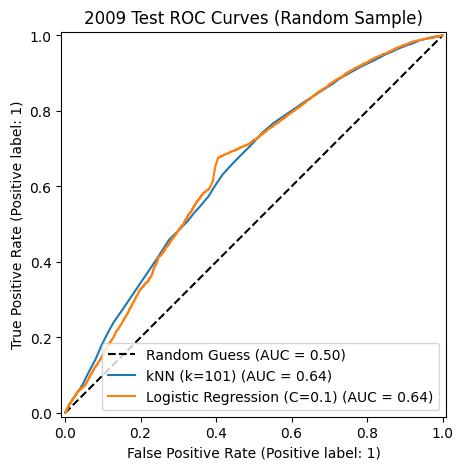

In [17]:
primary = run()

display(pd.read_csv("results/random/data_audit.csv"))
display(pd.read_csv("results/random/validation_search.csv").round(4))

display(primary[[
    "model",
    "validation_auc",
    "test_auc",
    "accuracy",
    "denial_recall",
    "error_on_denials",
    "error_on_approvals",
    "denied_as_approved",
    "approved_as_denied",
]].round(4))

display(Image(filename="results/random/test_roc.png"))

## 3. Primary metric and error analysis

ROC-AUC measures how well a model ranks actual approvals above actual denials using its approval scores. We also report denial precision, recall, and F1. The confusion matrices show how many applications each model got right or wrong for each outcome.

Among the filtered applications, the approval share rose from 64.2% in 2008 to 74.3% in 2009. The majority baseline achieved 74.29% accuracy on the 2009 test set while detecting zero denials.

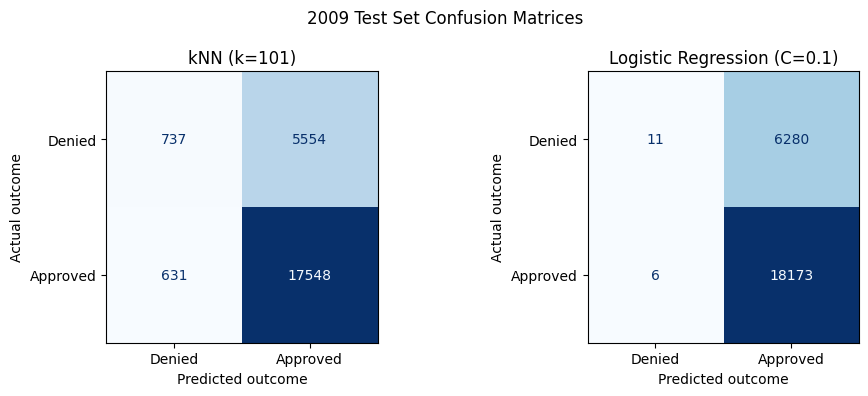

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

# Select the two trained models from the results table.
model_results = primary[primary["model"] != "Majority Baseline"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (_, row) in zip(axes, model_results.iterrows()):
    matrix = np.array([
        [row["denied_as_denied"], row["denied_as_approved"]],
        [row["approved_as_denied"], row["approved_as_approved"]],
    ], dtype=int)

    chart = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Denied", "Approved"],
    )
    chart.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(row["model"])
    ax.set_xlabel("Predicted outcome")
    ax.set_ylabel("Actual outcome")

fig.suptitle("2009 Test Set Confusion Matrices")
fig.tight_layout()
plt.show()

On the 2009 test set, kNN and logistic regression had nearly identical ROC-AUC scores (0.6413 and 0.6411). Using the selected models’ default prediction rules, kNN caught 737 of 6,291 denials and incorrectly predicted denial for 631 approvals. Logistic regression caught 11 denials and incorrectly predicted denial for 6 approvals. Both models missed most denials, and kNN caught more at the cost of more errors on actual approvals.

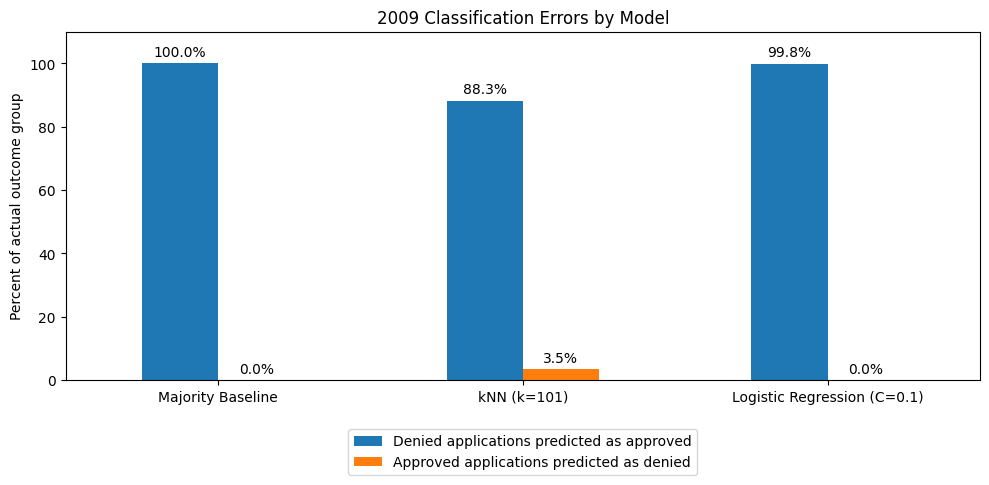

In [19]:
error_rates = primary.set_index("model")[
    ["error_on_denials", "error_on_approvals"]
] * 100

error_rates.columns = [
    "Denied applications predicted as approved",
    "Approved applications predicted as denied",
]

ax = error_rates.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("2009 Classification Errors by Model")
ax.set_xlabel("")
ax.set_ylabel("Percent of actual outcome group")
ax.set_ylim(0, 110)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

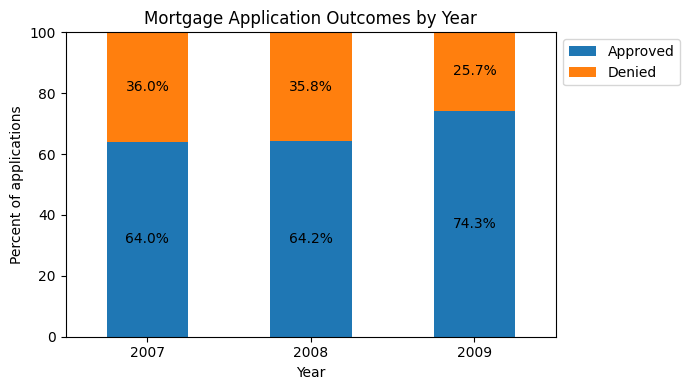

In [20]:
audit = pd.read_csv("results/random/data_audit.csv")

outcome_percentages = audit[["approved", "denied"]].div(
    audit["rows_after_filtering"], axis=0
) * 100

outcome_percentages.index = audit["split"].str[:4]
outcome_percentages.columns = ["Approved", "Denied"]

ax = outcome_percentages.plot(
    kind="bar", stacked=True, figsize=(7, 4), rot=0
)
ax.set_title("Mortgage Application Outcomes by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Percent of applications")
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", label_type="center")

plt.tight_layout()
plt.show()

## 4. Sensitivity Analysis
The plots also compare training and validation ROC-AUC, following Lab 4. A gap can reflect both how closely a model fits its training data and differences between years. We varied `k` and `C` using the same randomized dataset. On the 2008 validation set, kNN ROC-AUC increased from 0.6154 at k=5 to 0.6955 at k=101, the highest value among the settings we tested. Logistic regression was less sensitive across its tested settings, with ROC-AUC ranging from 0.6893 to 0.6914 and peaking at C=0.1.

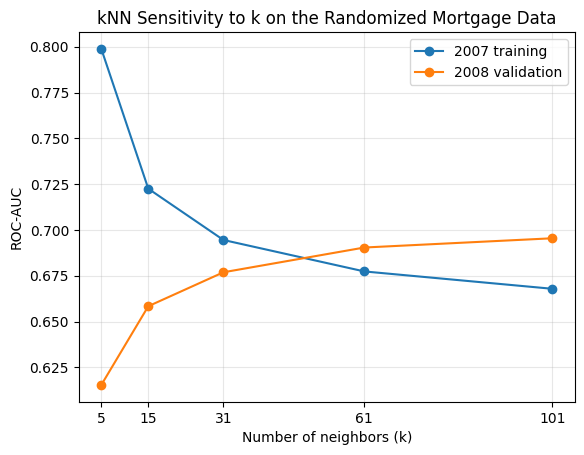

In [21]:
validation_results = pd.read_csv("results/random/validation_search.csv")

knn_results = validation_results[
    validation_results["model"] == "kNN"
].sort_values("value")

plt.plot(knn_results["value"], knn_results["training_auc"], marker="o", label="2007 training")
plt.plot(knn_results["value"], knn_results["validation_auc"], marker="o", label="2008 validation")
plt.legend()
plt.xticks(knn_results["value"])
plt.xlabel("Number of neighbors (k)")
plt.ylabel("ROC-AUC")
plt.title("kNN Sensitivity to k on the Randomized Mortgage Data")
plt.grid(alpha=0.3)
plt.show()

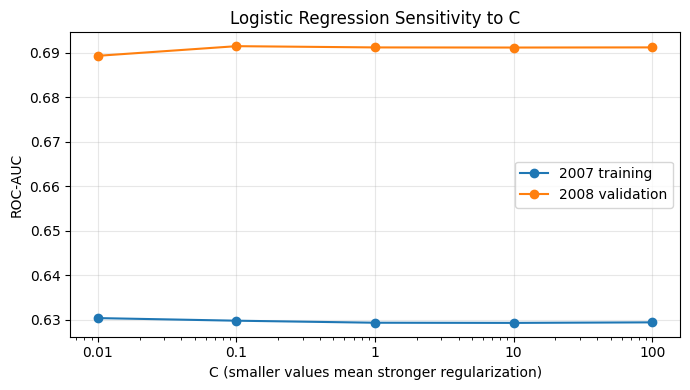

In [22]:
validation_results = pd.read_csv("results/random/validation_search.csv")

lr_results = validation_results[
    validation_results["model"] == "Logistic Regression"
].sort_values("value")

plt.figure(figsize=(7, 4))
plt.plot(lr_results["value"], lr_results["training_auc"], marker="o", label="2007 training")
plt.plot(lr_results["value"], lr_results["validation_auc"], marker="o", label="2008 validation")
plt.legend()
plt.xscale("log")
plt.xticks(lr_results["value"], [f"{c:g}" for c in lr_results["value"]])
plt.xlabel("C (smaller values mean stronger regularization)")
plt.ylabel("ROC-AUC")
plt.title("Logistic Regression Sensitivity to C")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Logistic regression threshold comparison

We use 2008 validation scores to choose the denial cutoff with the highest denial recall while incorrectly flagging at most 5% of actual approvals. We use 5% as an illustrative limit for this experiment. We then compare the selected cutoff with the default prediction rule on 2009. ROC-AUC stays the same because both rules use the same scores.

In [23]:
thresholds = pd.read_csv("results/random/threshold_comparison.csv")
display(thresholds.round(4))

extra_denials = thresholds.loc[1, "denials_caught"] - thresholds.loc[0, "denials_caught"]
extra_approvals = thresholds.loc[1, "approvals_flagged"] - thresholds.loc[0, "approvals_flagged"]
print(f"Change in denials caught: {extra_denials:+d}")
print(f"Change in actual approvals flagged: {extra_approvals:+d}")

,rule,denial_cutoff,denials_caught,denial_recall,approvals_flagged,approval_error_rate
0,Default,0.5000,11,0.0017,6,0.0003
1,Validation-selected,0.4425,622,0.0989,451,0.0248


Change in denials caught: +611
Change in actual approvals flagged: +445


## 6. Denial recall by loan purpose

We break down the selected models default predictions by loan purpose on the 2009 test set. The table shows how many applications and actual denials each group contains. Interpret recall with the denial count in mind, since a few predictions can have a large effect in a small group. Recall is undefined for a group with zero actual denials. The purpose values are the original dataset codes.

In [24]:
purpose_results = pd.read_csv("results/random/loan_purpose_errors.csv")
display(purpose_results[[
    "loan_purpose", "model", "applications", "actual_denials",
    "denials_caught", "denial_recall",
]].round(4))

,loan_purpose,model,applications,actual_denials,denials_caught,denial_recall
0,1,kNN (k=101),12647,2329,0,0.0000
1,2,kNN (k=101),700,434,170,0.3917
2,3,kNN (k=101),11123,3528,567,0.1607
3,1,Logistic Regression (C=0.1),12647,2329,0,0.0000
4,2,Logistic Regression (C=0.1),700,434,0,0.0000
5,3,Logistic Regression (C=0.1),11123,3528,11,0.0031


## 7. Single decision tree versus bagged trees

We compare an entropy-based decision tree with an ensemble of 100 entropy-based trees. Each ensemble tree is trained on a sample of 80% of the 2007 training rows drawn with replacement. The ensemble averages the trees’ predicted probabilities. Both approaches use the same four features, preprocessing, and five candidate depths.

The plot compares the two approaches at each matched depth on 2008. We select each approach’s depth by validation ROC-AUC and compare the selected models on 2009. If the selected depths differ, the test table compares the two tuned approaches. The matched-depth plot shows the effect of bagging with depth held fixed. The random seed is fixed at 42.

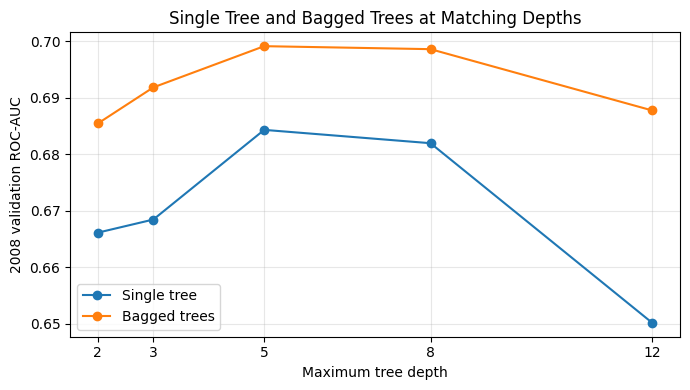

,model,max_depth,validation_auc,test_auc,denial_recall,error_on_approvals,denied_as_denied,approved_as_denied
0,Single tree,5,0.6843,0.6232,0.0795,0.0287,500,521
1,Bagged trees,5,0.6992,0.6424,0.1124,0.0315,707,572


In [25]:
tree_tuning = pd.read_csv("results/random/validation_search.csv")
tree_tuning = tree_tuning[tree_tuning["parameter"] == "max_depth"]

plt.figure(figsize=(7, 4))
for name in ["Single tree", "Bagged trees"]:
    scores = tree_tuning[tree_tuning["model"] == name].sort_values("value")
    plt.plot(scores["value"], scores["validation_auc"], marker="o", label=name)

plt.xticks(sorted(tree_tuning["value"].unique()))
plt.xlabel("Maximum tree depth")
plt.ylabel("2008 validation ROC-AUC")
plt.title("Single Tree and Bagged Trees at Matching Depths")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

tree_results = pd.read_csv("results/random/tree_comparison.csv")
display(tree_results[[
    "model", "max_depth", "validation_auc", "test_auc",
    "denial_recall", "error_on_approvals",
    "denied_as_denied", "approved_as_denied",
]].round(4))